In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import platform

fonts = {"Windows": "Malgun Gothic",
         "Darwin": "AppleGothic"}

name = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["font.family"] = name
plt.rcParams["axes.unicode_minus"] = False

In [59]:
df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]

for col in dates:
    df[col] = pd.to_datetime(df[col])

df.shape

(1030, 14)

In [60]:
before = len(df)

df = df.drop_duplicates()

print(before, "->", len(df))

1030 -> 1004


In [61]:
bad = df["quantity"] > 100

df.loc[bad, "quantity"] = (
    df.loc[bad, "total_sales"] /
    df.loc[bad, "unit_price"]
).round().astype(int)

diff = (
    df["total_sales"] -
    df["quantity"] * df["unit_price"]
).abs()

print(
    "고친 줄 :", bad.sum(),
    " 수량 최대 :", df["quantity"].max(),
    " 총액 안 맞는 줄 :", (diff > 1).sum()
)

고친 줄 : 22  수량 최대 : 99  총액 안 맞는 줄 : 0


In [62]:
df["date_error"] = (
    df["delivery_date"] < df["shipping_date"]
)

print("날짜 오류 :", df["date_error"].sum())

df.to_csv("sales_clean.csv", index=False)

df.shape

날짜 오류 : 147


(1004, 15)

배송 기간 (도착일 − 배송일) 은 보통 며칠인가 

평균 : 22.050469483568076
중앙값 : 2.0


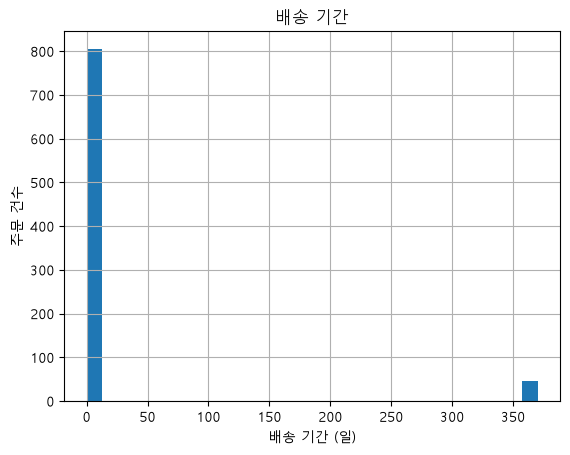

300일 초과 건수 : 47
11     365
20     369
29     365
41     368
68     364
99     367
110    365
131    369
165    368
192    367
199    364
215    368
326    367
334    368
338    367
361    367
383    370
397    366
412    368
425    370
527    365
542    365
543    365
546    367
585    364
592    368
608    365
633    370
638    365
685    366
694    369
747    364
750    367
775    366
784    368
786    364
810    365
813    367
828    366
853    367
884    366
887    369
888    365
895    364
936    368
939    369
982    366
dtype: int64
    shipping_date delivery_date
11     2023-01-15    2024-01-15
20     2023-01-23    2024-01-27
29     2023-02-03    2024-02-03
41     2023-02-14    2024-02-17
68     2023-03-14    2024-03-12
99     2023-04-11    2024-04-12
110    2023-04-25    2024-04-24
131    2023-05-13    2024-05-16
165    2023-06-16    2024-06-18
192    2023-07-13    2024-07-14
199    2023-07-22    2024-07-20
215    2023-08-05    2024-08-07
326    2023-11-26    2024-11-27
334   

In [63]:
valid = df[
    (~df["date_error"]) &
    df["delivery_date"].notna()
]

days = (
    valid["delivery_date"] -
    valid["shipping_date"]
).dt.days

print("평균 :", days.mean())
print("중앙값 :", days.median())

days.hist(bins=30)

plt.title("배송 기간")
plt.xlabel("배송 기간 (일)")
plt.ylabel("주문 건수")
plt.show()

print("300일 초과 건수 :", (days > 300).sum())
print(days[days > 300])

print(
    valid.loc[
        days > 300,
        ["shipping_date", "delivery_date"]
    ]
)

제외 전 평균 : 22.050469483568076
제외 전 중앙값 : 2.0
제외 후 평균 : 1.9316770186335404
제외 후 중앙값 : 2.0


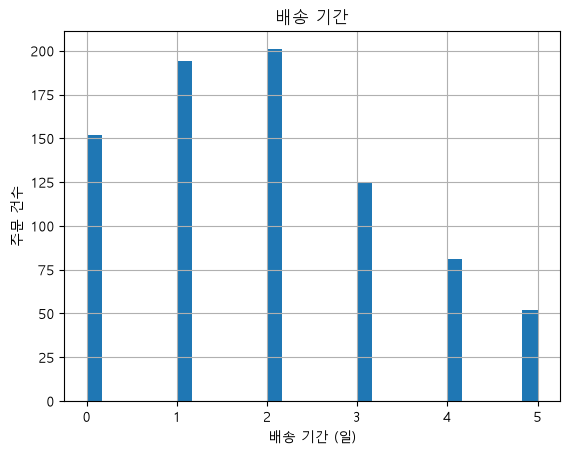

In [64]:
normal_days = days[days <= 300]

print("제외 전 평균 :", days.mean())
print("제외 전 중앙값 :", days.median())

print("제외 후 평균 :", normal_days.mean())
print("제외 후 중앙값 :", normal_days.median())

valid = df[
    (~df["date_error"]) &
    df["delivery_date"].notna() 
]

days = (
    valid["delivery_date"] -
    valid["shipping_date"]
).dt.days

days = days[days <= 300]

days.hist(bins=30)

plt.title("배송 기간")
plt.xlabel("배송 기간 (일)")
plt.ylabel("주문 건수")
plt.show()



전체 배송 기간의 평균은 22.05일 정도이며 중앙값은 2일이었고 300일 초과 기록은 47건이며, 이로 인해 평균과 중앙값이 크게 달라졌다. 300일 초과 건의 실제 기록을 살펴보니 364~370사이로 분포 되어있었고 이는 날짜 오류로 의심되어 평균 배송 기간 산출에서 제외 하였고 이후 평균은 1.93, 중앙값은 2로 평균과 중앙값이 비슷해졌다. 

만족도가 낮을수록 반품이 많은가

satisfaction
1.0     7.589286
2.0    11.956522
3.0     7.812500
4.0     8.720930
5.0     6.930693
Name: status, dtype: float64


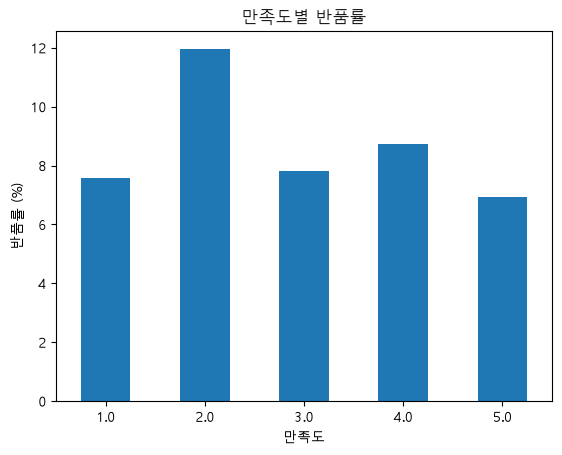

In [65]:
returned = df["status"] == "반품"

return_rate = (
    returned.groupby(df["satisfaction"]).mean() * 100
)

print(return_rate)

return_rate.plot.bar()

plt.title("만족도별 반품률")
plt.xlabel("만족도")
plt.ylabel("반품률 (%)")
plt.xticks(rotation=0)
plt.show()

만족도 4점 고객의 반품률이 8.72%로 1점과 3점 고객보다 높은 것으로 보아, 만족도와 반품률 사이에 일관된 음의 상관관계가 있다고 판단하기는 어렵다.

다만 만족도 2점 고객의 반품률이 11.96%로 가장 높고, 5점 고객은 6.93%로 가장 낮아 낮은 만족도가 높은 반품률과 연관될 가능성을 확인할 수 있다.

카테고리 매출 1위의 이유는 건수 · 단가 · 수량
중 무엇인가

In [66]:
result = df.groupby("category").agg(
    order_count=("category", "size"),
    total_sales=("total_sales", "sum"),
    avg_unit_price=("unit_price", "mean"),
    avg_quantity=("quantity", "mean")
)

result = result.sort_values(
    "total_sales",
    ascending=False
)

result.round(2)

,order_count,total_sales,avg_unit_price,avg_quantity
category,,,,
가구,213,2.843337e+09,257322.91,51.04
식품,210,2.513274e+09,255232.93,47.31
전자제품,207,2.471628e+09,249651.61,47.96
도서,204,2.453240e+09,238500.64,49.50
의류,170,2.181904e+09,249447.16,51.61


매출 1위인 가구는 주문 건수 213건으로 가장 많았으며, 평균 단가 또한 가장 높았다. 평균 구매 수량은 51.04개로 2위를 기록했으며, 1위와는 0.57개, 5위와는 3.73개의 차이를 보여 전반적으로 여러 지표에서 높은 순위를 기록했다.

반면 의류는 평균 구매 수량이 51.61개로 가장 많았음에도 총매출은 가장 낮았다. 이를 통해 총매출은 평균 구매 수량만으로 결정되는 것이 아니라 주문 건수와 상품 단가 등 여러 요인을 종합적으로 고려해야 함을 알 수 있다.